# Run previous notebook

In [54]:
from IPython.utils.capture import capture_output

with capture_output():
    get_ipython().run_line_magic('run', '01_eda_freight.ipynb')

# 1. Baseline Model

In [55]:
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,Freight_total,Freight_5days,...,sunhour,totalsnow,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,0.0,44.55,37.05,...,6.8,0.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,0.0,41.55,37.05,...,3.1,0.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,0.0,41.55,37.05,...,8.4,0.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,0.0,40.05,37.05,...,8.4,0.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,0.0,38.55,37.05,...,5.0,0.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


In [56]:
col = 'Freight_total'

# Garante a ordem temporal (se tiveres uma coluna Date)
df_sorted = df_complete.sort_values('Date').reset_index(drop=True)
y = df_sorted[col]

# 1) Maior amplitude em 5 linhas seguidas (como antes)
amplitude = y.rolling(5).max() - y.rolling(5).min()
print('Maior amplitude em 5 linhas:', amplitude.max())

# 2) Previsão = média dos 5 dias anteriores (shift(1) exclui o próprio dia)
pred_mean5 = y.shift(1).rolling(5).mean()
erro_mean5 = (y - pred_mean5).abs()

# 3) Previsão = valor do dia anterior
pred_naive = y.shift(1)
erro_naive = (y - pred_naive).abs()

# Resultados
for nome, erro, pred in [('Média dos 5 dias anteriores', erro_mean5, pred_mean5),
                         ('Valor do dia anterior', erro_naive, pred_naive)]:
    i = erro.idxmax()
    print(f'\n{nome}')
    print('  Erro máximo:', round(erro[i], 2))
    print('  Erro médio (MAE):', round(erro.mean(), 2))
    print('  Valor real:', y[i], '| Previsão:', round(pred[i], 2))
    print('  Linha:', i)

Maior amplitude em 5 linhas: 225.28

Média dos 5 dias anteriores
  Erro máximo: 177.62
  Erro médio (MAE): 3.99
  Valor real: 159.72 | Previsão: 337.34
  Linha: 1453

Valor do dia anterior
  Erro máximo: 112.63
  Erro médio (MAE): 1.46
  Valor real: 256.74 | Previsão: 369.37
  Linha: 1452


In [57]:
# Previsões (usam só informação até ao dia t)
df_complete['pred_hoje']     = df_complete['Freight_total']
df_complete['pred_media5']   = df_complete['Freight_total'].rolling(5).mean()
# Hoje + variação dos últimos 5 dias = 2*y(t) - y(t-5)
df_complete['pred_momentum'] = df_complete['Freight_total'] + df_complete['Freight_total'].diff(5)

previsores = {
    'Preço de hoje': 'pred_hoje',
    'Média dos últimos 5 dias': 'pred_media5',
    'Hoje + variação 5 dias': 'pred_momentum',
}

# Mesmas linhas para os três métodos (media5 e momentum geram NaN nas primeiras linhas)
av = df_complete.dropna(subset=list(previsores.values()) + ['Freight_5days'])

def metricas(y_true, y_pred):
    erro = y_true - y_pred
    return {
        'MAE': erro.abs().mean(),
        'RMSE': np.sqrt((erro ** 2).mean()),
        'Erro máx': erro.abs().max(),
    }

# Todos os dias
resultados = pd.DataFrame({
    nome: metricas(av['Freight_5days'], av[col])
    for nome, col in previsores.items()
}).T

print(f'Nº de previsões avaliadas: {len(av)}')
display(resultados.round(2))

# Só dias extremos (top 10% do preço real a 5 dias)
extremo = av['Freight_5days'] >= av['Freight_5days'].quantile(0.90)

resultados_ext = pd.DataFrame({
    nome: metricas(av.loc[extremo, 'Freight_5days'], av.loc[extremo, col])
    for nome, col in previsores.items()
}).T

print('Dias extremos:')
display(resultados_ext.round(2))

Nº de previsões avaliadas: 1363


,MAE,RMSE,Erro máx
Preço de hoje,6.58,16.42,228.82
Média dos últimos 5 dias,8.68,19.86,214.87
Hoje + variação 5 dias,7.70,20.12,257.84


Dias extremos:


,MAE,RMSE,Erro máx
Preço de hoje,23.50,43.09,228.82
Média dos últimos 5 dias,27.56,44.66,214.87
Hoje + variação 5 dias,24.24,45.59,257.84


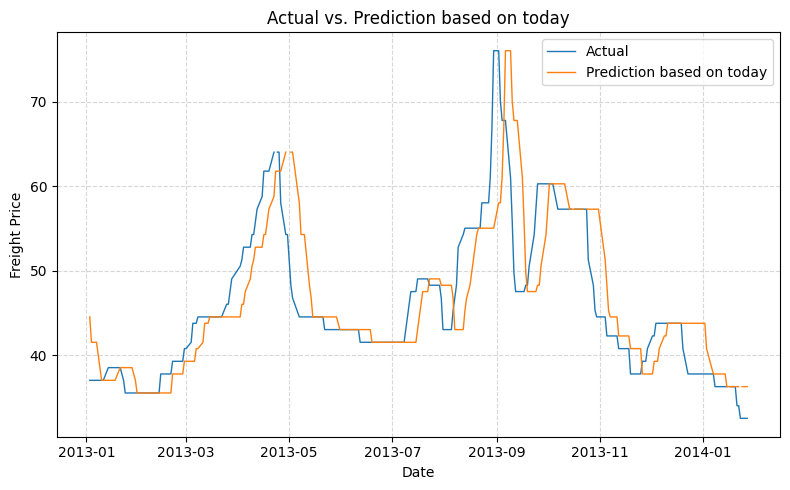

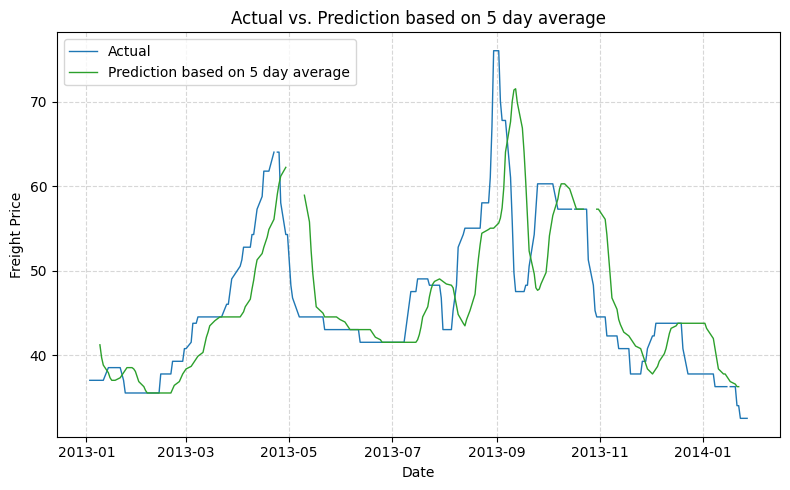

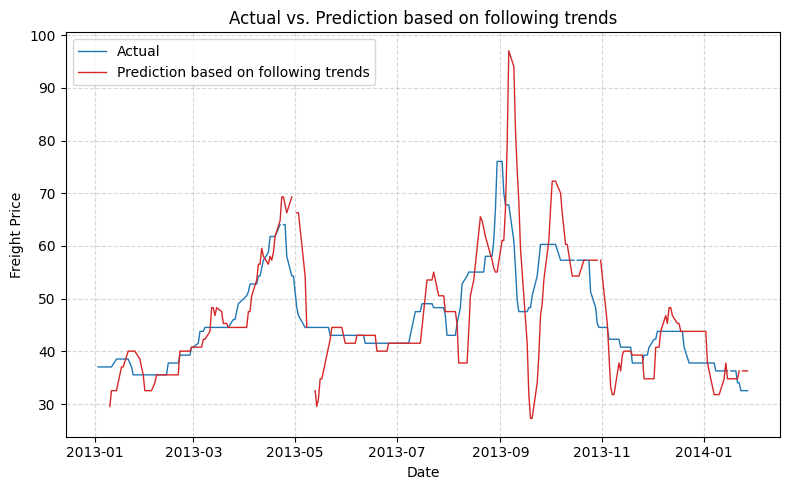

In [72]:
year = int(365 * 5 / 7)
subset = df_complete.iloc[:year]
x = subset['Date']

# Define (column_name, legend_label, line_color) for each baseline
baselines = [
    ('pred_hoje', 'Prediction based on today', '#ff7f0e'),
    ('pred_media5', 'Prediction based on 5 day average', '#2ca02c'),
    ('pred_momentum', 'Prediction based on following trends', '#d62728'),
]

for col, label, color in baselines:
    fig, ax = plt.subplots(figsize=(8, 5))
    
    ax.plot(x, subset['Freight_5days'], label='Actual', color='#1f77b4', linewidth=1)
    ax.plot(x, subset[col], label=label, color=color, linewidth=1)
    
    ax.set(title=f'Actual vs. {label}', xlabel='Date', ylabel='Freight Price')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')
    
    plt.tight_layout()

plt.show()

Cada hipotese de baseline tem vantagens e desvantagens. Pelos resultados a melhor baseline é assumir o preço de hoje para a previsao.
A media dos ultimos 5 dias tende  atrasar o sinal da trend na previsao piorando os resultados. 
A tentativa de seguir a tendencia (Hoje + variação) resulta em menores erros no inicio de tendencias mas erros amplificados quando o crescimento/diminuição de preço muda de sentido.

Por enquanto a baseline escolhida é o preço do proprio dia

# 2. Features

- Que features são mais importantes para o modelo?
- Que features são redundantes?
- Que tipo de split fazer? Cross-validation? Ter a certeza que nao existe data leakage
- Que modelos usar?
- Experimentar PCA para reduzir Weather features e gas price features?

Eliminar features claramente redundantes

In [58]:
df_complete.drop(columns=['Freight', 'freight_ar', 'windgust', 'wind_dir', 'weather_code', 'moon_phase', 'moon_illumination'], inplace=True)

In [59]:
corr_above30 = (
    correlation_matrix['Freight_5days']
    .loc[lambda s: s > 0.30]            # arbitrary value could be 0.4, 0.5 etc
    .drop('Freight_5days', errors='ignore')   # remove the target's correlation with itself (1.0)
    .sort_values(ascending=False)
    .rename('Correlation')
    .to_frame()
)

corr_above30.round(3)

,Correlation
Freight_total,0.962
Freight,0.961
freight_ar,0.800
Kaub_level,0.742
Date,0.729
Brent_flat,0.610
Diesel_Flat,0.526
Heating_Flat,0.493
humidity,0.393
maxtemp,0.385


Encoding features

In [60]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90529 entries, 0 to 90528
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1469 non-null   datetime64[ns]
 1   Mogas_Flat            1469 non-null   float64       
 2   Brent_flat            1469 non-null   float64       
 3   Diesel_Flat           1469 non-null   float64       
 4   Heating_Flat          1469 non-null   float64       
 5   Kaub_level            1456 non-null   float64       
 6   Freight_total         1454 non-null   float64       
 7   Freight_5days         1449 non-null   float64       
 8   avgtemp               1469 non-null   float64       
 9   cloudcover            1469 non-null   float64       
 10  dewpoint              1469 non-null   float64       
 11  feelslike             1469 non-null   float64       
 12  heatindex             1469 non-null   float64       
 13  humidity        

Encoding Date into cos e sin

In [61]:
doy = df_complete['Date'].dt.dayofyear
df_complete['Date_sin'] = np.sin(2 * np.pi * doy / 365.25)
df_complete['Date_cos'] = np.cos(2 * np.pi * doy / 365.25)

Encoding Weather Description

In [62]:
df_complete = pd.get_dummies(df_complete, columns=['weather_descriptions'], prefix='weather', dtype=int)

In [63]:
df_complete.columns

Index(['Date', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat', 'Heating_Flat',
       'Kaub_level', 'Freight_total', 'Freight_5days', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'precip', 'pressure', 'sunhour', 'totalsnow', 'visibility',
       'wind_degree', 'wind_speed', 'windchill', 'pred_hoje', 'pred_media5',
       'pred_momentum', 'Date_sin', 'Date_cos', 'weather_['Clear']',
       'weather_['Cloudy']', 'weather_['Fog']', 'weather_['Freezing fog']',
       'weather_['Light rain shower']', 'weather_['Light rain']',
       'weather_['Mist']', 'weather_['Moderate or heavy rain shower']',
       'weather_['Moderate rain']', 'weather_['Overcast']',
       'weather_['Partly cloudy']',
       'weather_['Patchy light rain with thunder']',
       'weather_['Patchy rain possible']',
       'weather_['Thundery outbreaks possible']'],
      dtype='object')